# SNN จำแนกชนิดนก (ปรับปรุงแล้ว)
เปลี่ยนจากโค้ดเดิม: แก้ class ปลอม `TrainSet`, ปรับขนาดภาพได้ที่ตัวแปรเดียว (`IMG_SIZE`),
เพิ่ม normalization/augmentation, BatchNorm, อ่านผลจาก logits ที่ไม่ใช่ spike count, AMP, scheduler, บันทึกโมเดล + ฟังก์ชันทำนายภาพ

## วิธีเตรียม Google Drive API สำหรับ VS Code

1. เปิด Google Cloud Console แล้วสร้างหรือเลือก Project
2. เปิดใช้งาน **Google Drive API**
3. ตั้งค่า OAuth consent screen และเพิ่มบัญชี Google เป็น Test user หากแอปอยู่ในโหมด Testing
4. สร้าง OAuth Client ID ประเภท **Desktop app** แล้วดาวน์โหลดไฟล์ JSON
5. เปลี่ยนชื่อไฟล์เป็น `credentials.json` และวางไว้ในโฟลเดอร์เดียวกับ Notebook
6. เปิดโฟลเดอร์ `Image_Dataset` ใน Google Drive แล้วคัดลอก Folder ID จาก URL มาใส่ใน `DRIVE_DATASET_FOLDER_ID`
7. รันเซลล์ติดตั้งไลบรารี จากนั้นรันเซลล์ตั้งค่าเพื่อเข้าสู่ระบบ Google ผ่าน Browser

**ความปลอดภัย:** อย่าแชร์ `credentials.json` หรือ `token.json` และเพิ่มทั้งสองไฟล์ใน `.gitignore` รูปภาพจะถูกดาวน์โหลดมาเก็บใน `data/Image_Dataset` บนเครื่องเพื่อให้ PyTorch อ่านได้ การเชื่อมต่อแบบนี้เป็นการดาวน์โหลดผ่าน API ไม่ใช่การ mount Drive

หากต้องการดาวน์โหลด/อัปเดตรูปจาก Drive อีกครั้ง ให้ตั้ง `REFRESH_DATASET = True` แล้วรันเซลล์ตั้งค่าใหม่ เมื่อเป็น `False` จะใช้ไฟล์ที่มีอยู่ในเครื่องเป็น cache


In [1]:
# ติดตั้งไลบรารีที่จำเป็นใน VS Code
%pip install -q snntorch google-api-python-client google-auth-httplib2 google-auth-oauthlib

# Google Drive API: OAuth Desktop App
import os
from pathlib import Path
from google_auth_oauthlib.flow import InstalledAppFlow
from google.auth.transport.requests import Request
from google.oauth2.credentials import Credentials
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload
import io

SCOPES = ["https://www.googleapis.com/auth/drive.readonly"]
PROJECT_DIR = Path.cwd()
CREDENTIALS_FILE = PROJECT_DIR / "credentials.json"
TOKEN_FILE = PROJECT_DIR / "token.json"

def get_drive_service():
    creds = None
    if TOKEN_FILE.exists():
        creds = Credentials.from_authorized_user_file(str(TOKEN_FILE), SCOPES)
    if creds and creds.expired and creds.refresh_token:
        creds.refresh(Request())
    if not creds or not creds.valid:
        if not CREDENTIALS_FILE.exists():
            raise FileNotFoundError("ไม่พบ credentials.json กรุณาสร้าง OAuth Client ID แบบ Desktop app จาก Google Cloud Console แล้ววางไว้ในโฟลเดอร์โปรเจกต์")
        flow = InstalledAppFlow.from_client_secrets_file(str(CREDENTIALS_FILE), SCOPES)
        creds = flow.run_local_server(port=0)
    TOKEN_FILE.write_text(creds.to_json(), encoding="utf-8")
    return build("drive", "v3", credentials=creds)

print("เตรียม Google Drive API เรียบร้อย")


เตรียม Google Drive API เรียบร้อย


## 1) ตั้งค่า (แก้ที่นี่ที่เดียว)

In [2]:
import os, json, time, random
from pathlib import Path
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import snntorch as snn
from snntorch import surrogate
import matplotlib.pyplot as plt

# ---------------- CONFIG ----------------
# ใส่ Folder ID ของโฟลเดอร์ Image_Dataset ใน Google Drive
# URL ตัวอย่าง: https://drive.google.com/drive/folders/1AbCdEfGh...
DRIVE_DATASET_FOLDER_ID = "1AFS1AeNVTdU0rA4VqNyZA2w5pI2pxhcrPROJECT_DIR = Path(r"D:\GAME\PJ\Bird-Classification")
DATASET_ROOT = PROJECT_DIR / "data" / "Image_Dataset"
EXCLUDE_DIRS = ["TrainSet"]
REFRESH_DATASET = False  # True เพื่อดาวน์โหลดไฟล์ใหม่/อัปเดตไฟล์เดิม
IMG_SIZE = 128
BATCH_SIZE = 32
NUM_STEPS = 6
EPOCHS = 30
LR = 2e-3
VAL_SPLIT = 0.2
SEED = 42
SAVE_PATH = PROJECT_DIR / "outputs" / "snn_birds_best.pt"
# ----------------------------------------

def download_drive_folder(service, folder_id, destination, refresh=False):
    """ดาวน์โหลดโฟลเดอร์ Google Drive แบบ recursive และคงโครงสร้างโฟลเดอร์"""
    destination = Path(destination)
    destination.mkdir(parents=True, exist_ok=True)

    def list_children(parent_id):
        items, page_token = [], None
        while True:
            response = service.files().list(
                q=f"'{parent_id}' in parents and trashed = false",
                fields="nextPageToken, files(id, name, mimeType, size, md5Checksum)",
                pageSize=1000, pageToken=page_token,
                supportsAllDrives=True, includeItemsFromAllDrives=True
            ).execute()
            items.extend(response.get("files", []))
            page_token = response.get("nextPageToken")
            if not page_token:
                return items

    def download_file(file_id, target):
        target.parent.mkdir(parents=True, exist_ok=True)
        request = service.files().get_media(fileId=file_id, supportsAllDrives=True)
        temp_target = target.with_name(target.name + ".download")
        with open(temp_target, "wb") as fh:
            downloader = MediaIoBaseDownload(fh, request)
            done = False
            while not done:
                _, done = downloader.next_chunk()
        os.replace(temp_target, target)

    def walk(parent_id, local_dir):
        local_dir.mkdir(parents=True, exist_ok=True)
        for item in list_children(parent_id):
            name = item["name"]
            if name.startswith("."):
                continue
            target = local_dir / name
            if item["mimeType"] == "application/vnd.google-apps.folder":
                walk(item["id"], target)
            elif item["mimeType"] == "application/vnd.google-apps.shortcut":
                print(f"ข้าม shortcut: {name}")
            else:
                if target.exists() and not refresh:
                    continue
                download_file(item["id"], target)

    walk(folder_id, destination)
    print(f"ดาวน์โหลด/ตรวจสอบ Dataset แล้ว: {destination}")

if not DRIVE_DATASET_FOLDER_ID or DRIVE_DATASET_FOLDER_ID.startswith("ใส่_"):
    raise ValueError("กรุณากำหนด DRIVE_DATASET_FOLDER_ID เป็น Folder ID ของ Image_Dataset ก่อนรัน")

drive_service = get_drive_service()
download_drive_folder(drive_service, DRIVE_DATASET_FOLDER_ID, DATASET_ROOT, REFRESH_DATASET)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
# Auto: ใช้ CUDA เมื่อพร้อม มิฉะนั้นใช้ CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"
print("device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
SAVE_PATH.parent.mkdir(parents=True, exist_ok=True)


ดาวน์โหลด/ตรวจสอบ Dataset แล้ว: D:\GAME\PJ\Bird-Classification\data\Image_Dataset
device: cuda
GPU: NVIDIA GeForce RTX 5060 Ti


## 2) ข้อมูล

In [4]:
class BirdFolder(datasets.ImageFolder):
    # ตัดโฟลเดอร์ที่ไม่ใช่นกออกตั้งแต่ตอนหาคลาส
    def __init__(self, root, exclude=(), **kw):
        self._exclude = set(exclude)
        super().__init__(root, **kw)
    def find_classes(self, directory):
        classes = sorted(e.name for e in os.scandir(directory)
                         if e.is_dir() and e.name not in self._exclude and not e.name.startswith('.'))
        return classes, {c: i for i, c in enumerate(classes)}

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.3, 0.3, 0.3, 0.05),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

base = BirdFolder(str(DATASET_ROOT), EXCLUDE_DIRS)
classes = base.classes
NUM_CLASSES = len(classes)
targets = np.array(base.targets)
print("classes:", classes)
if NUM_CLASSES < 2:
    raise ValueError(f"พบคลาสเพียง {NUM_CLASSES} คลาส กรุณาตรวจสอบโครงสร้าง Image_Dataset")
if min(np.bincount(targets)) < 2:
    raise ValueError("มีคลาสที่มีภาพน้อยกว่า 2 ภาพ จึงแบ่ง train/validation แบบ stratified ไม่ได้")

tr_idx, va_idx = train_test_split(np.arange(len(base)), test_size=VAL_SPLIT,
                                  stratify=targets, random_state=SEED)
train_ds = Subset(BirdFolder(str(DATASET_ROOT), EXCLUDE_DIRS, transform=train_tf), tr_idx)
val_ds = Subset(BirdFolder(str(DATASET_ROOT), EXCLUDE_DIRS, transform=eval_tf), va_idx)
counts = np.bincount(targets[tr_idx], minlength=NUM_CLASSES)
print("train per class:", dict(zip(classes, counts)))
class_w = torch.tensor(counts.sum() / (NUM_CLASSES * counts), dtype=torch.float32).to(device)

# num_workers=0 ช่วยลดปัญหา multiprocessing บน Windows/VS Code Notebook
NUM_WORKERS = 0
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
                          drop_last=(len(train_ds) >= BATCH_SIZE))
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
print(f"Train {len(train_ds)} | Val {len(val_ds)}")


classes: ['Common-Kingfisher', 'Common-Myna', 'House-Crow', 'Indian-Peacock', 'Indian-Pitta', 'Ruddy-Shelduck', 'Sarus-Crane']
train per class: {'Common-Kingfisher': np.int64(960), 'Common-Myna': np.int64(960), 'House-Crow': np.int64(960), 'Indian-Peacock': np.int64(960), 'Indian-Pitta': np.int64(960), 'Ruddy-Shelduck': np.int64(960), 'Sarus-Crane': np.int64(960)}
Train 6720 | Val 1680


## 3) โมเดล SNN
- Conv → BatchNorm → MaxPool → LIF (pool ก่อน LIF เพื่อลดงานและแรม)
- **Direct encoding**: เลเยอร์แรกคำนวณครั้งเดียวนอกลูป time step (เร็วขึ้น)
- ผลลัพธ์ = logits จาก FC (ไม่ใช่ spike) เฉลี่ยตามเวลา → gradient ไหลดี ไม่ติดที่ ln(C)

In [5]:
class SpikingBirdNet(nn.Module):
    def __init__(self, num_classes, T=6, widths=(32, 64, 128, 256), beta=0.9, drop=0.3):
        super().__init__()
        self.T = T
        grad = surrogate.fast_sigmoid(slope=25)
        self.convs, self.bns, self.lifs = nn.ModuleList(), nn.ModuleList(), nn.ModuleList()
        c = 3
        for w in widths:
            self.convs.append(nn.Conv2d(c, w, 3, padding=1, bias=False))
            self.bns.append(nn.BatchNorm2d(w))
            self.lifs.append(snn.Leaky(beta=beta, learn_beta=True, spike_grad=grad))
            c = w
        self.pool = nn.MaxPool2d(2)
        self.drop = nn.Dropout(drop)
        self.fc = nn.Linear(c, num_classes)

    def forward(self, x):
        mems = [lif.init_leaky() for lif in self.lifs]
        cur0 = self.pool(self.bns[0](self.convs[0](x)))     # คำนวณครั้งเดียว
        out = 0
        for _ in range(self.T):
            spk, mems[0] = self.lifs[0](cur0, mems[0])
            for i in range(1, len(self.convs)):
                cur = self.pool(self.bns[i](self.convs[i](spk)))
                spk, mems[i] = self.lifs[i](cur, mems[i])
            feat = spk.mean(dim=(2, 3))                      # spike rate ต่อ channel
            out = out + self.fc(self.drop(feat))
        return out / self.T

model = SpikingBirdNet(NUM_CLASSES, T=NUM_STEPS).to(device).to(memory_format=torch.channels_last)
print(f'params: {sum(p.numel() for p in model.parameters())/1e6:.2f}M')

criterion = nn.CrossEntropyLoss(weight=class_w, label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR, epochs=EPOCHS, steps_per_epoch=len(train_loader), pct_start=0.2)
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

params: 0.39M


## 4) เทรน

In [6]:
def run_epoch(loader, train):
    model.train(train)
    tot_loss, correct, n = 0.0, 0, 0
    ctx = torch.enable_grad() if train else torch.no_grad()
    with ctx:
        for x, y in loader:
            x = x.to(device, non_blocking=True).to(memory_format=torch.channels_last)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer); scaler.update(); scheduler.step()
            tot_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += y.size(0)
    return tot_loss / n, 100 * correct / n

history, best_acc = [], 0.0
for ep in range(1, EPOCHS + 1):
    t0 = time.time()
    tl, ta = run_epoch(train_loader, True)
    vl, va = run_epoch(val_loader, False)
    history.append((tl, ta, vl, va))
    flag = ''
    if va > best_acc:
        best_acc = va
        torch.save({'model': model.state_dict(), 'classes': classes,
                    'img_size': IMG_SIZE, 'num_steps': NUM_STEPS, 'mean': MEAN, 'std': STD}, SAVE_PATH)
        flag = ' *saved'
    print(f'Ep {ep:02d}/{EPOCHS} | train {tl:.3f}/{ta:.1f}% | val {vl:.3f}/{va:.1f}% | {time.time()-t0:.0f}s{flag}')
print('best val acc:', best_acc)

Ep 01/30 | train 1.795/31.4% | val 1.712/38.8% | 176s *saved
Ep 02/30 | train 1.679/40.1% | val 1.680/38.9% | 111s *saved
Ep 03/30 | train 1.615/43.8% | val 1.571/43.4% | 111s *saved
Ep 04/30 | train 1.543/48.0% | val 1.498/48.3% | 113s *saved
Ep 05/30 | train 1.456/52.6% | val 1.456/52.6% | 111s *saved
Ep 06/30 | train 1.401/56.1% | val 1.378/55.2% | 112s *saved
Ep 07/30 | train 1.342/58.7% | val 1.261/62.3% | 112s *saved
Ep 08/30 | train 1.289/61.9% | val 1.318/59.7% | 115s
Ep 09/30 | train 1.245/64.1% | val 1.182/67.6% | 114s *saved
Ep 10/30 | train 1.194/66.9% | val 1.164/68.4% | 112s *saved
Ep 11/30 | train 1.159/67.9% | val 1.144/69.9% | 117s *saved
Ep 12/30 | train 1.130/70.1% | val 1.084/73.6% | 118s *saved
Ep 13/30 | train 1.095/72.1% | val 1.076/72.4% | 115s
Ep 14/30 | train 1.072/73.3% | val 0.999/76.4% | 108s *saved
Ep 15/30 | train 1.041/74.9% | val 0.961/79.2% | 102s *saved
Ep 16/30 | train 1.004/76.9% | val 0.982/78.1% | 104s
Ep 17/30 | train 0.983/77.8% | val 0.930/82.4

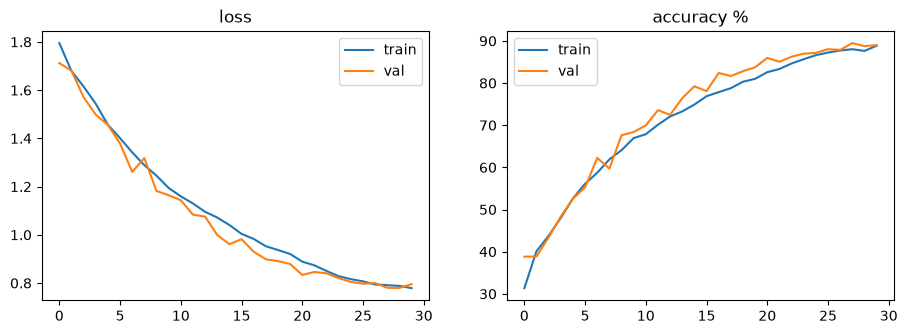

In [7]:
h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(h[:, 0], label='train'); ax[0].plot(h[:, 2], label='val'); ax[0].set_title('loss'); ax[0].legend()
ax[1].plot(h[:, 1], label='train'); ax[1].plot(h[:, 3], label='val'); ax[1].set_title('accuracy %'); ax[1].legend()
plt.show()

## 5) ประเมินผลรายชนิด

                   precision    recall  f1-score   support

Common-Kingfisher      0.892     0.933     0.912       240
      Common-Myna      0.918     0.842     0.878       240
       House-Crow      0.842     0.821     0.831       240
   Indian-Peacock      0.920     0.863     0.890       240
     Indian-Pitta      0.904     0.938     0.920       240
   Ruddy-Shelduck      0.970     0.933     0.951       240
      Sarus-Crane      0.833     0.938     0.882       240

         accuracy                          0.895      1680
        macro avg      0.897     0.895     0.895      1680
     weighted avg      0.897     0.895     0.895      1680



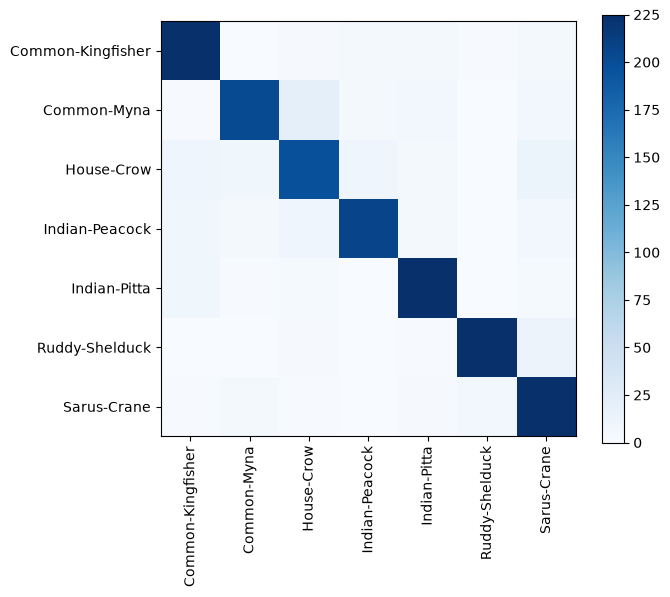

In [8]:
ckpt = torch.load(SAVE_PATH, map_location=device)
model.load_state_dict(ckpt['model']); model.eval()
ys, ps = [], []
with torch.no_grad():
    for x, y in val_loader:
        p = model(x.to(device)).argmax(1).cpu()
        ys += y.tolist(); ps += p.tolist()
print(classification_report(ys, ps, target_names=classes, digits=3))

cm = confusion_matrix(ys, ps)
plt.figure(figsize=(7, 6)); plt.imshow(cm, cmap='Blues')
plt.xticks(range(NUM_CLASSES), classes, rotation=90); plt.yticks(range(NUM_CLASSES), classes)
plt.colorbar(); plt.tight_layout(); plt.show()

## 6) ทำนายภาพใหม่

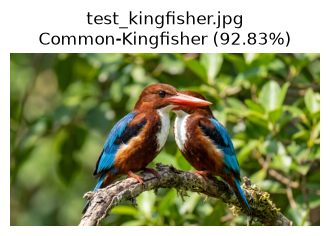

ไฟล์: test_kingfisher.jpg
ผลการทำนาย Top-3: [('Common-Kingfisher', 0.9283364415168762), ('Indian-Peacock', 0.05153018236160278), ('Indian-Pitta', 0.009719237685203552)]
คำตอบสุดท้าย: Common-Kingfisher (ความมั่นใจ 92.83%)
--------------------------------------------------


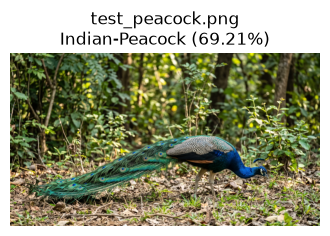

ไฟล์: test_peacock.png
ผลการทำนาย Top-3: [('Indian-Peacock', 0.6920830607414246), ('Common-Myna', 0.14963854849338531), ('House-Crow', 0.0662948340177536)]
คำตอบสุดท้าย: Indian-Peacock (ความมั่นใจ 69.21%)
--------------------------------------------------


In [17]:
from PIL import Image
import matplotlib.pyplot as plt

def predict(path, topk=3):
    tf = transforms.Compose([
        transforms.Resize((ckpt['img_size'],) * 2),
        transforms.ToTensor(),
        transforms.Normalize(ckpt['mean'], ckpt['std'])
    ])
    x = tf(Image.open(path).convert('RGB')).unsqueeze(0).to(device)
    with torch.no_grad():
        prob = torch.softmax(model(x), 1)[0].cpu()
    top = prob.topk(min(topk, len(ckpt['classes'])))
    return [(ckpt['classes'][i], float(p)) for p, i in zip(top.values, top.indices)]

test_dir = PROJECT_DIR / "test_images"
valid_exts = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
image_files = sorted([p for p in test_dir.iterdir() if p.is_file() and p.suffix.lower() in valid_exts])

if not image_files:
    print(f"ไม่พบไฟล์รูปภาพใน {test_dir}")
else:
    for image_path in image_files:
        predictions = predict(str(image_path))
        final_class, final_confidence = predictions[0]  # อันดับ 1 จาก topk อยู่ในตำแหน่งแรกเสมอ

        img = Image.open(image_path).convert("RGB")
        plt.figure(figsize=(4, 4))  # ปรับขนาดภาพให้เล็กลงกำลังดี (4x4 นิ้ว)
        plt.imshow(img)
        plt.title(f"{image_path.name}\n{final_class} ({final_confidence:.2%})")
        plt.axis("off")
        plt.show()

        print(f"ไฟล์: {image_path.name}")
        print("ผลการทำนาย Top-3:", predictions)
        print(f"คำตอบสุดท้าย: {final_class} (ความมั่นใจ {final_confidence:.2%})")
        print("-" * 50)